## NB08 — Treinamento e Avaliação de Modelos

**Entrada:** `data/load/dataset_ml_model.csv` — 76.218 linhas × 25 colunas (gerado pelo NB07)

**Objetivo:** Treinar e avaliar o modelo de detecção de anomalias **Isolation Forest, LOF e One Class SVM** sobre o
dataset de propostas de licitações de Pernambuco (2020–2024).

In [59]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

os.makedirs('data/load', exist_ok=True)
print('Setup OK')

Setup OK


In [60]:
df = pd.read_csv('data/load/dataset_ml_model.csv')

print(f'Shape: {df.shape}')
print(f'\nColunas ({len(df.columns)}):')
print(list(df.columns))
print('\nTipos de dados:')
print(df.dtypes)
df.head(3)

Shape: (76218, 25)

Colunas (25):
['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_para_eleicao', 'ano_eleitoral', 'pre_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidadeNome', 'porte', 'cnae_fiscal', 'descricao_situacao_cadastral']

Tipos de dados:
orgaoEntidadeCnpj                 int64
anoCompraPncp                     int64
sequencialCompraPncp              int64
numeroItem                        int64
cnpj_forn_norm                    int64
desvio_item_estimado            float64
n_propostas_item                  int64
fornecedor_unico                  int64
ano                               int64
mes                               int64
trimestre                         int64
dia_semana                        int64
dias_para_eleica

,orgaoEntidadeCnpj,anoCompraPncp,sequencialCompraPncp,numeroItem,cnpj_forn_norm,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,...,fornecedor_fora_pe,tipo_fornecedor,idade_empresa_anos,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidadeNome,porte,cnae_fiscal,descricao_situacao_cadastral
0,2030715000112,2023,1,1,44051659000142,-0.354518,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1
1,2030715000112,2023,3,1,44051659000142,-0.019704,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1
2,508903000188,2022,324,1,32212672000157,0.000000,1,1,2023,1,...,1,1,8.659822,0,0,0,2,0,-1,1


---
### 1. Preparação: Remoção de Identificadores

In [61]:
identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df = df.drop(identificadores, axis=1)
df

,desvio_item_estimado,n_propostas_item,fornecedor_unico,ano,mes,trimestre,dia_semana,dias_para_eleicao,ano_eleitoral,pre_eleitoral_180d,fornecedor_fora_pe,tipo_fornecedor,idade_empresa_anos,empresa_nova,opcao_pelo_mei,opcao_pelo_simples,modalidadeNome,porte,cnae_fiscal,descricao_situacao_cadastral
0,-0.354518,1,1,2023,1,1,0,636,0,0,1,1,8.659822,0,0,0,2,0,-1,1
1,-0.019704,1,1,2023,1,1,1,635,0,0,1,1,8.659822,0,0,0,2,0,-1,1
2,0.000000,1,1,2023,1,1,4,625,0,0,1,1,8.659822,0,0,0,2,0,-1,1
3,-0.006719,1,1,2023,1,1,0,636,0,0,1,1,8.659822,0,0,0,2,0,-1,1
4,0.000000,1,1,2023,1,1,0,622,0,0,1,1,8.659822,0,0,0,4,0,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76213,-0.000100,1,1,2024,12,4,2,73,1,1,1,1,8.659822,0,0,0,4,0,-1,1
76214,-0.000100,1,1,2024,12,4,2,73,1,1,1,1,8.659822,0,0,0,4,0,-1,1
76215,-0.000089,1,1,2024,12,4,2,73,1,1,1,1,8.659822,0,0,0,4,0,-1,1
76216,-0.000092,1,1,2024,12,4,2,73,1,1,1,1,8.659822,0,0,0,4,0,-1,1


---
### 2. Treinamento 

### Isolation Forest

O **Isolation Forest** detecta anomalias isolando observações com árvores de decisão aleatórias.
Pontos anômalos são isolados com menos cortes do que pontos normais, resultando em um
`anomaly_score` mais negativo.

**Hiperparâmetros:**

| Parâmetro | Valor | Justificativa |
|---|---|---|
| `n_estimators` | 100 | Número de árvores — bom equilíbrio entre estabilidade e custo computacional |
| `contamination` | 0.01 | 1% de anomalias esperadas — conservador, alinhado com Araújo et al. (2024) |
| `max_samples` | 256 | Amostras por árvore — padrão do sklearn, eficiente em datasets grandes |
| `random_state` | 42 | Reprodutibilidade dos resultados |

In [62]:
# Train Isolation Forest
iso_forest = IsolationForest(n_estimators=100,
                            contamination=0.01, # Expected proportion of anomalies
                            max_samples=256, # Number of samples used to train each tree
                            random_state=42)
iso_forest.fit(df)

IsolationForest(contamination=0.01, max_samples=256, random_state=42)

In [63]:
# 1 = normal ; -1 anomalo
feature_cols = df.columns.tolist()
df['anomaly_score'] = iso_forest.decision_function(df[feature_cols])
df['anomaly'] = iso_forest.predict(df[feature_cols])
df['anomaly'].value_counts()

anomaly
 1    75456
-1      762
Name: count, dtype: int64

### Resultados e Visualizações - Isolation Forest

#### Gráfico de dispersão (score × índice)

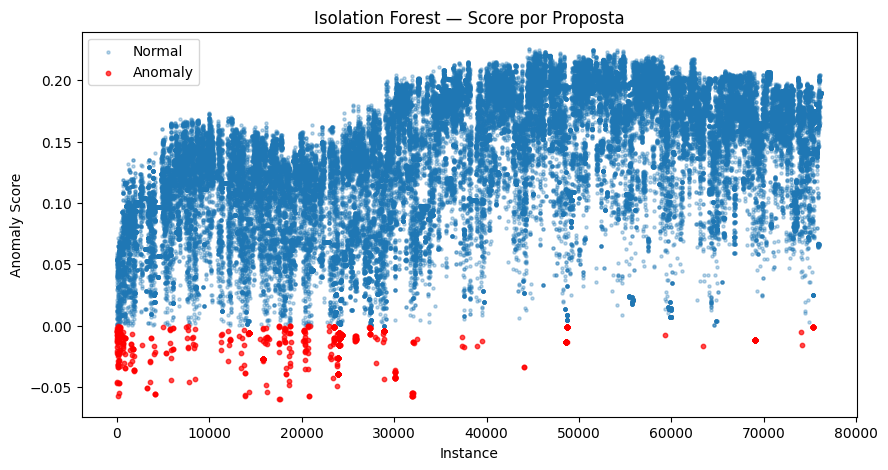

In [64]:
plt.figure(figsize=(10, 5))

normal = df[df['anomaly'] == 1]
plt.scatter(normal.index, normal['anomaly_score'], label='Normal', alpha=0.3, s=5)

anomalies = df[df['anomaly'] == -1]
plt.scatter(anomalies.index, anomalies['anomaly_score'], label='Anomaly', alpha=0.7, s=10, color='red')

plt.xlabel("Instance")
plt.ylabel("Anomaly Score")
plt.title("Isolation Forest — Score por Proposta")
plt.legend()
plt.show()

#### Histograma de distribuição

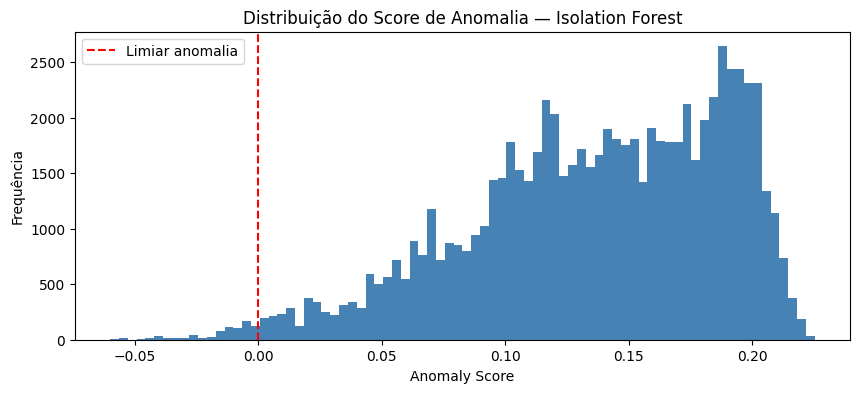

Total de anomalias detectadas: 762 (1.0%)


In [65]:
# Distribuição do anomaly_score
plt.figure(figsize=(10, 4))
plt.hist(df['anomaly_score'], bins=80, color='steelblue', edgecolor='none')
plt.axvline(df[df['anomaly'] == -1]['anomaly_score'].max(), color='red', linestyle='--', label='Limiar anomalia')
plt.xlabel("Anomaly Score")
plt.ylabel("Frequência")
plt.title("Distribuição do Score de Anomalia — Isolation Forest")
plt.legend()
plt.show()

print(f"Total de anomalias detectadas: {(df['anomaly'] == -1).sum()} ({(df['anomaly'] == -1).mean():.1%})")

---
### Local Outlier Factor - LOF

In [ ]:
# testar com valores diferentes de neighbors
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01)

lof_predictions = lof.fit_predict(df[feature_cols])
lof_scores = -lof.negative_outlier_factor_

# (Higher score = more anomalous. Standard values close to or > 1 indicate outliers)
df['lof_anomaly_score'] = lof_scores
df['lof_anomaly'] = lof_predictions

print(f"Total de propostas: {len(df)}")
print(f"Anomalias detectadas: {(df['lof_anomaly'] == -1).sum()} ({(df['lof_anomaly'] == -1).mean():.1%})")
df['lof_anomaly'].value_counts()

Total de propostas: 76218
Anomalias detectadas: 760 (1.0%)


/Users/lgs/Library/Python/3.9/lib/python/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


lof_anomaly
 1    75458
-1      760
Name: count, dtype: int64

### Resultados e Visualizações - LOF

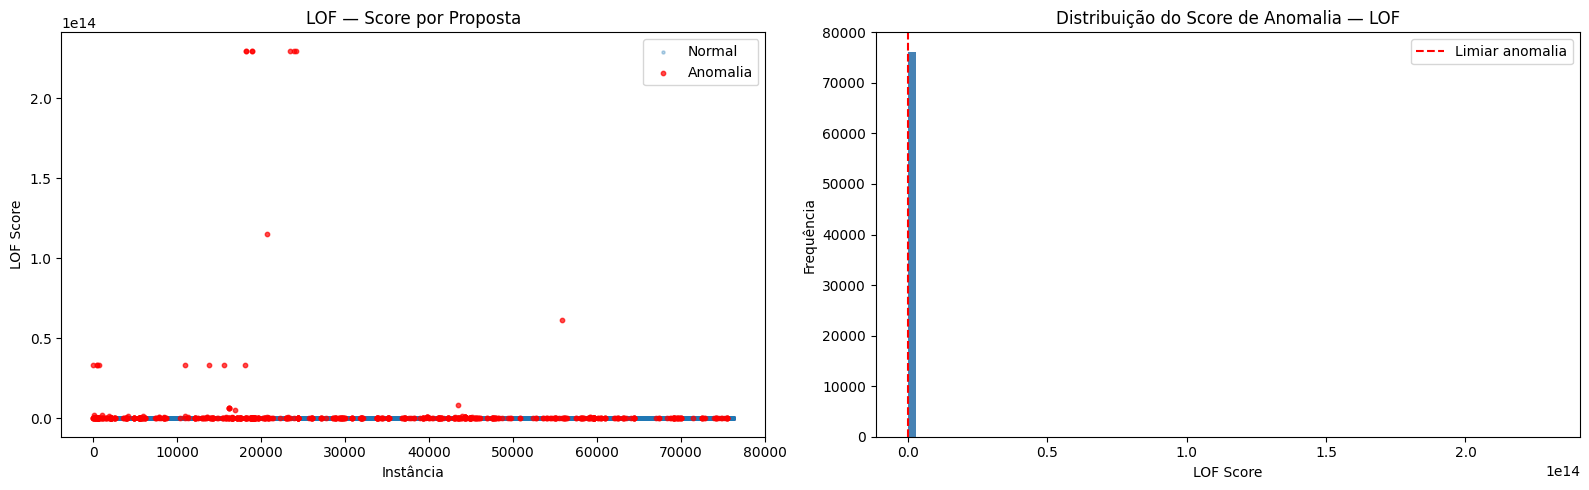

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

normal = df[df['lof_anomaly'] == 1]
anomalies = df[df['lof_anomaly'] == -1]

axes[0].scatter(normal.index, normal['lof_anomaly_score'], label='Normal', alpha=0.3, s=5)
axes[0].scatter(anomalies.index, anomalies['lof_anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')
axes[0].set_xlabel("Instância")
axes[0].set_ylabel("LOF Score")
axes[0].set_title("LOF — Score por Proposta")
axes[0].legend()

axes[1].hist(df['lof_anomaly_score'], bins=80, color='steelblue', edgecolor='none')
axes[1].axvline(df[df['lof_anomaly'] == -1]['lof_anomaly_score'].min(),
                color='red', linestyle='--', label='Limiar anomalia')
axes[1].set_xlabel("LOF Score")
axes[1].set_ylabel("Frequência")
axes[1].set_title("Distribuição do Score de Anomalia — LOF")
axes[1].legend()

plt.tight_layout()
plt.show()

--- 
### One Class SVM

In [68]:
ocsvm = OneClassSVM(kernel='rbf', nu=0.01, gamma='scale')
ocsvm.fit(df[feature_cols])

ocsvm_predictions = ocsvm.predict(df[feature_cols])
ocsvm_scores = ocsvm.decision_function(df[feature_cols])

df['ocsvm_anomaly_score'] = ocsvm_scores
df['ocsvm_anomaly'] = ocsvm_predictions

print(f"Total de propostas: {len(df)}")
print(f"Anomalias detectadas: {(df['ocsvm_anomaly'] == -1).sum()} ({(df['ocsvm_anomaly'] == -1).mean():.1%})")
df['ocsvm_anomaly'].value_counts()

Total de propostas: 76218
Anomalias detectadas: 20843 (27.3%)


ocsvm_anomaly
 1    55375
-1    20843
Name: count, dtype: int64

### Resultados e Visualizações - One Class SVM

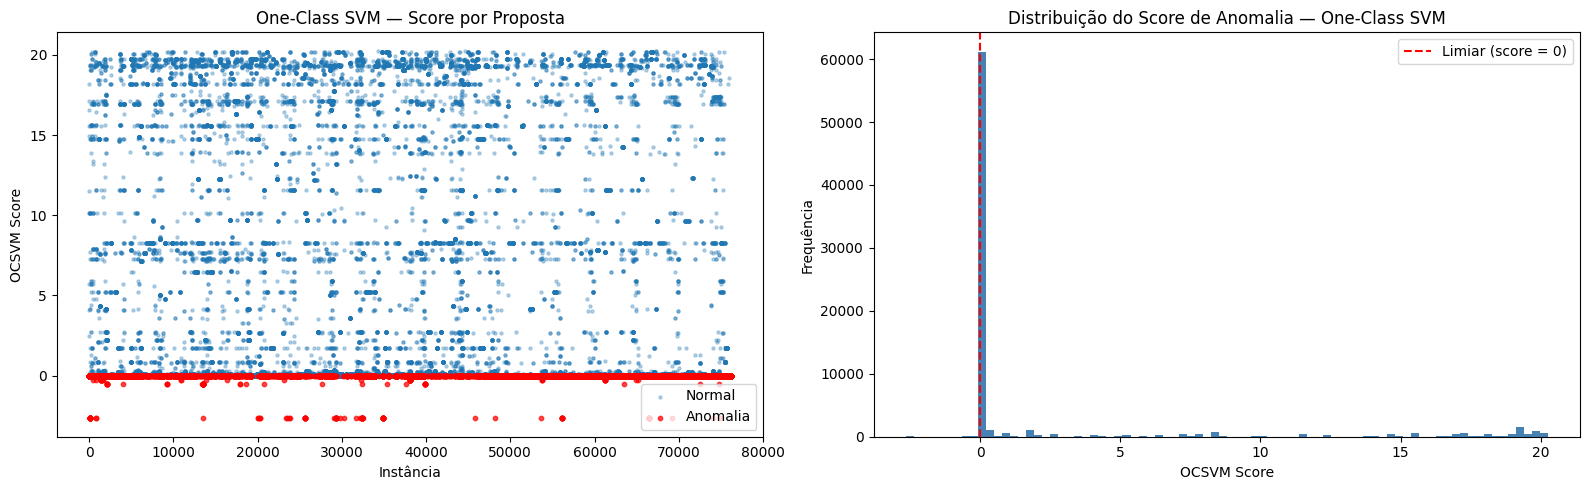

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scatter: score × índice
normal = df[df['ocsvm_anomaly'] == 1]
anomalies = df[df['ocsvm_anomaly'] == -1]

axes[0].scatter(normal.index, normal['ocsvm_anomaly_score'], label='Normal', alpha=0.3, s=5)
axes[0].scatter(anomalies.index, anomalies['ocsvm_anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')
axes[0].set_xlabel("Instância")
axes[0].set_ylabel("OCSVM Score")
axes[0].set_title("One-Class SVM — Score por Proposta")
axes[0].legend()

# Histograma
axes[1].hist(df['ocsvm_anomaly_score'], bins=80, color='steelblue', edgecolor='none')
axes[1].axvline(0, color='red', linestyle='--', label='Limiar (score = 0)')
axes[1].set_xlabel("OCSVM Score")
axes[1].set_ylabel("Frequência")
axes[1].set_title("Distribuição do Score de Anomalia — One-Class SVM")
axes[1].legend()

plt.tight_layout()
plt.show()

### Nomalização das Features - One Class SVM

In [70]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[feature_cols])

ocsvm = OneClassSVM(kernel='rbf', nu=0.01, gamma='scale')
ocsvm.fit(X_scaled)

ocsvm_predictions = ocsvm.predict(X_scaled)
ocsvm_scores = ocsvm.decision_function(X_scaled)

df['ocsvm_anomaly_score'] = ocsvm_scores
df['ocsvm_anomaly'] = ocsvm_predictions

print(f"Total de propostas: {len(df)}")
print(f"Anomalias detectadas (pós normalização): {(df['ocsvm_anomaly'] == -1).sum()} ({(df['ocsvm_anomaly'] == -1).mean():.1%})")
df['ocsvm_anomaly'].value_counts()

Total de propostas: 76218
Anomalias detectadas (pós normalização): 1586 (2.1%)


ocsvm_anomaly
 1    74632
-1     1586
Name: count, dtype: int64

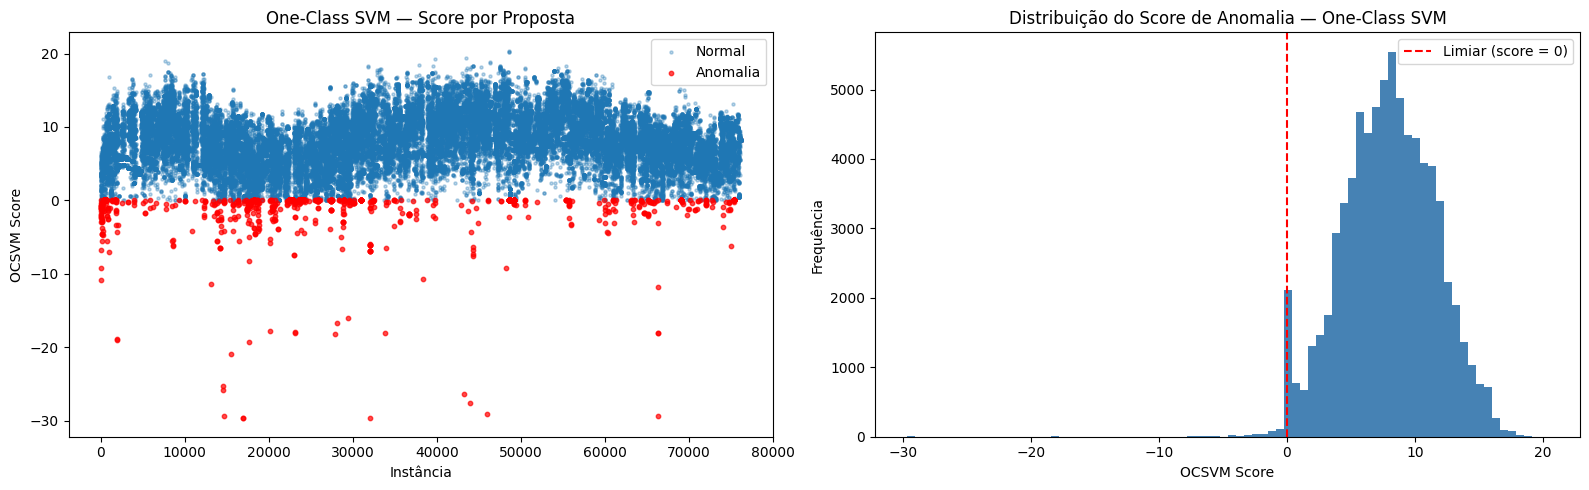

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scatter: score × índice
normal = df[df['ocsvm_anomaly'] == 1]
anomalies = df[df['ocsvm_anomaly'] == -1]

axes[0].scatter(normal.index, normal['ocsvm_anomaly_score'], label='Normal', alpha=0.3, s=5)
axes[0].scatter(anomalies.index, anomalies['ocsvm_anomaly_score'], label='Anomalia', alpha=0.7, s=10, color='red')
axes[0].set_xlabel("Instância")
axes[0].set_ylabel("OCSVM Score")
axes[0].set_title("One-Class SVM — Score por Proposta")
axes[0].legend()

# Histograma
axes[1].hist(df['ocsvm_anomaly_score'], bins=80, color='steelblue', edgecolor='none')
axes[1].axvline(0, color='red', linestyle='--', label='Limiar (score = 0)')
axes[1].set_xlabel("OCSVM Score")
axes[1].set_ylabel("Frequência")
axes[1].set_title("Distribuição do Score de Anomalia — One-Class SVM")
axes[1].legend()

plt.tight_layout()
plt.show()

---